```
Index No: KIC-BSCCSAI-251P-012
Name: Najimudeen Mohamed Najahi
(BSc in Computer Science with Artificial Intelligence, NIBM KIC)
```
- GitHub: [Code](https://github.com/MohamedNajahi/gallstone-disease-prediction-ml.git)

# Phase 2: Technical Application — Option A

## Baseline Implementation and Comparative Evaluation of Machine Learning Models for Gallstone Disease Prediction

### Reference Paper
Esen et al. (2024), *Early prediction of gallstone disease with a machine learning-based method from bioimpedance and laboratory data.*

### Objective
The objective of this practical implementation is to develop baseline machine learning models for gallstone disease classification and compare their performance with the original research.

Logistic Regression will be used as a simple baseline, while Gradient Boosting will be implemented to reproduce the model family that achieved the highest reported accuracy.

Additional classifiers will be evaluated to investigate differences in predictive performance and model generalization.

### Phase Roadmap
1. Dataset verification
    - Check 319 records, features, target labels and data quality
2. Exploratory data analysis
    - Statistics, missing values, skewness, outliers and correlations
3. Stratified 70/30 split
    - Separate training and test data
4. Simple baseline
    - Train and evaluate Logistic Regression using training CV
5. Gradient Boosting reproduction
    - Train the authors' best-reported algorithm
6. Ten-algorithm comparison
    - RF, MLP, LR, NB, DT, KNN, SVM, GB, AdaBoost, XGBoost
7. Hyperparameter optimization
    - ANOVA, pipelines and 10-fold GridSearchCV
8. Final evaluation
    - Precision, recall, F1, ROC-AUC, accuracy and confusion matrix
9. Paper comparison
    - Compare the same algorithms with the supplied research results
10. Critical discussion
    - Explain differences, overfitting, limitations and conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

RANDOM_STATE = 42

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)



NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1


# 2.Load dataset

In [2]:
df = pd.read_csv("dataset-uci.csv")

print("Dataset Shape:", df.shape)

print("\nFirst five records:")
df.head()

print("\nDataset columns:")
df.columns.tolist()

Dataset Shape: (319, 39)

First five records:

Dataset columns:


['Gallstone Status',
 'Age',
 'Gender',
 'Comorbidity',
 'Coronary Artery Disease (CAD)',
 'Hypothyroidism',
 'Hyperlipidemia',
 'Diabetes Mellitus (DM)',
 'Height',
 'Weight',
 'Body Mass Index (BMI)',
 'Total Body Water (TBW)',
 'Extracellular Water (ECW)',
 'Intracellular Water (ICW)',
 'Extracellular Fluid/Total Body Water (ECF/TBW)',
 'Total Body Fat Ratio (TBFR) (%)',
 'Lean Mass (LM) (%)',
 'Body Protein Content (Protein) (%)',
 'Visceral Fat Rating (VFR)',
 'Bone Mass (BM)',
 'Muscle Mass (MM)',
 'Obesity (%)',
 'Total Fat Content (TFC)',
 'Visceral Fat Area (VFA)',
 'Visceral Muscle Area (VMA) (Kg)',
 'Hepatic Fat Accumulation (HFA)',
 'Glucose',
 'Total Cholesterol (TC)',
 'Low Density Lipoprotein (LDL)',
 'High Density Lipoprotein (HDL)',
 'Triglyceride',
 'Aspartat Aminotransferaz (AST)',
 'Alanin Aminotransferaz (ALT)',
 'Alkaline Phosphatase (ALP)',
 'Creatinine',
 'Glomerular Filtration Rate (GFR)',
 'C-Reactive Protein (CRP)',
 'Hemoglobin (HGB)',
 'Vitamin D']

In [3]:
TARGET = "Gallstone Status"

print("Target column exists:", TARGET in df.columns)

if TARGET in df.columns:
    print("\nTarget distribution:")
    print(df[TARGET].value_counts(dropna=False).sort_index())

    print("\nTarget percentages:")
    print(
        df[TARGET]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

Target column exists: True

Target distribution:
Gallstone Status
0    161
1    158
Name: count, dtype: int64

Target percentages:
Gallstone Status
0    50.470219
1    49.529781
Name: proportion, dtype: float64


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumber of input features:")
print(df.shape[1] - 1)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                           

# 2 .Exploratory Data Analysis (EDA)

Check missing values and duplicates

In [5]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
df.isnull().sum().sort_values(ascending=False).head(10)

Total missing values: 0
Duplicate rows: 0

Missing values by column:


Gallstone Status                 0
Age                              0
Gender                           0
Comorbidity                      0
Coronary Artery Disease (CAD)    0
Hypothyroidism                   0
Hyperlipidemia                   0
Diabetes Mellitus (DM)           0
Height                           0
Weight                           0
dtype: int64

In [6]:
stats = df.drop(columns=["Gallstone Status"]).describe().T

stats[["mean", "std", "min", "25%", "50%", "75%", "max"]]


,mean,std,min,25%,50%,75%,max
Age,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50
Body Mass Index (BMI),28.877116,5.313707,17.40,25.250,28.300000,31.850,49.70


In [7]:
X_eda = df.drop(columns=["Gallstone Status"])

skewness = X_eda.skew().sort_values(
    key=abs,
    ascending=False
)

pd.DataFrame({"Feature": skewness.index,"Skewness": skewness.values}).head(15)

,Feature,Skewness
0,Obesity (%),16.873233
1,Alanin Aminotransferaz (ALT),7.276949
2,Aspartat Aminotransferaz (AST),6.994506
3,High Density Lipoprotein (HDL),6.528948
4,Hyperlipidemia,6.103333
5,Glucose,5.937810
6,Hypothyroidism,5.725508
7,C-Reactive Protein (CRP),5.411104
8,Coronary Artery Disease (CAD),4.883282
9,Triglyceride,2.786394


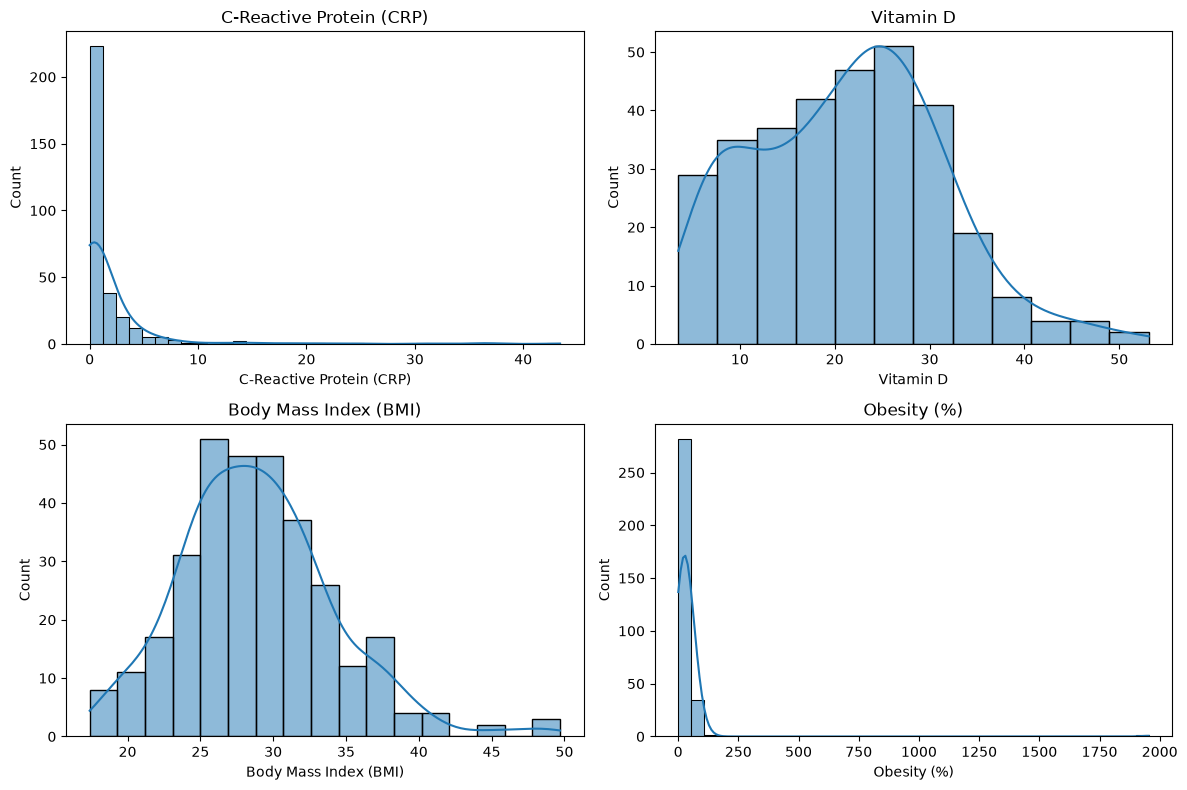

In [8]:
features = ["C-Reactive Protein (CRP)","Vitamin D","Body Mass Index (BMI)","Obesity (%)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.histplot(
        df[feature].dropna(),
        kde=True,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

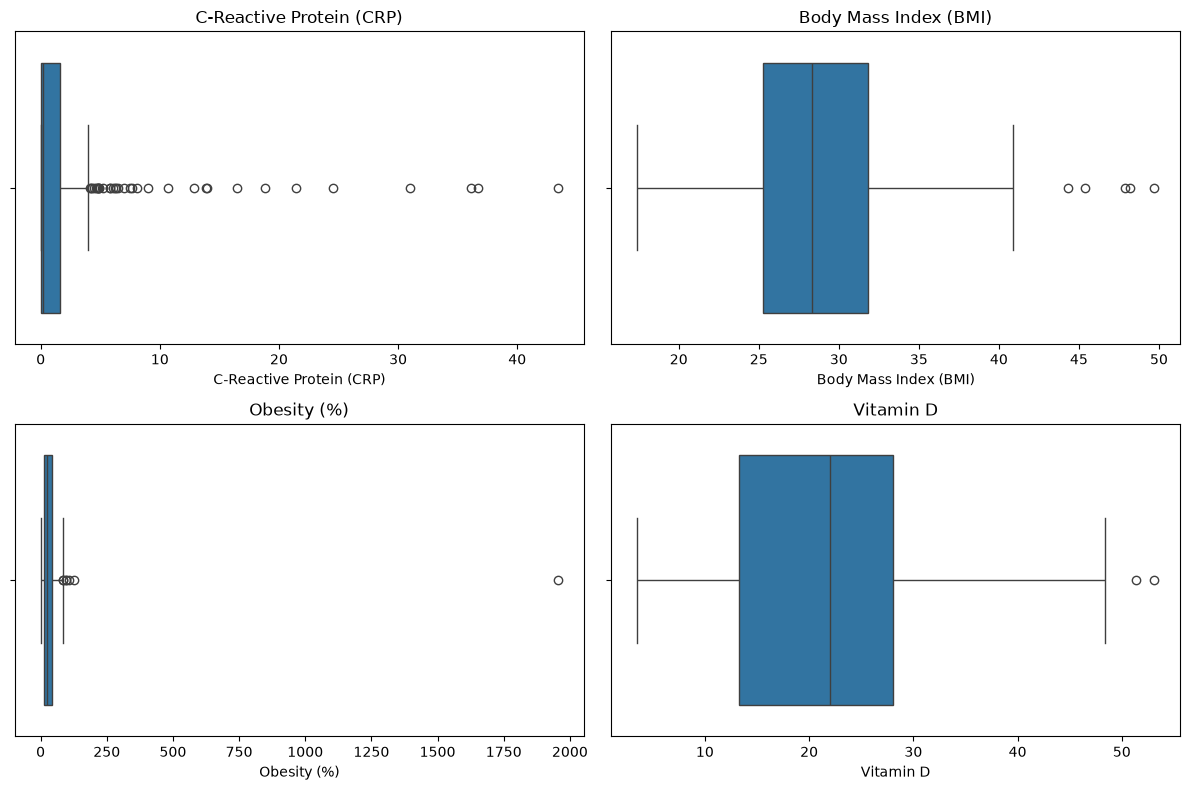

In [9]:
features = [
    "C-Reactive Protein (CRP)",
    "Body Mass Index (BMI)",
    "Obesity (%)",
    "Vitamin D"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        x=df[feature],
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [10]:
eda_df = df.copy()

eda_df["Disease Present"] = (
    eda_df["Gallstone Status"] == 0
).astype(int)

correlations = (
    eda_df.drop(columns=["Gallstone Status"])
    .corr(numeric_only=True)["Disease Present"]
    .drop("Disease Present")
    .sort_values(key=abs, ascending=False)
)

correlations.head(15).to_frame(name="Correlation with Disease Presence")


,Correlation with Disease Presence
Vitamin D,0.354873
C-Reactive Protein (CRP),-0.281995
Lean Mass (LM) (%),0.225749
Total Body Fat Ratio (TBFR) (%),-0.225470
Bone Mass (BM),0.216570
Hemoglobin (HGB),0.196872
Extracellular Water (ECW),0.178436
Total Fat Content (TFC),-0.170158
Extracellular Fluid/Total Body Water (ECF/TBW),0.169826
Hyperlipidemia,-0.161901


```The exploratory analysis showed that the dataset contains 319 observations and 38 predictors, with no missing values or duplicate records. Several continuous features, including CRP, Glucose, AST and ALT, were strongly right-skewed. An extreme observation was also identified in Obesity (%). Therefore, preprocessing and model validation must be handled carefully. I retained the original observations for the baseline implementation and used training-only preprocessing to prevent data leakage.```

## 3. Train-Test Splitting

The dataset was divided into training and testing subsets using a stratified 70/30 split.

The target variable is Gallstone Status:
- 0 = Gallstones present
- 1 = Gallstones absent

Stratification was applied to preserve the original class proportions in both subsets.

A fixed random state of 42 was used for reproducibility.

In [11]:
# Input features
X = df.drop(columns=["Gallstone Status"])

# Target variable
y = df["Gallstone Status"].astype(int)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget labels:")
print(y.value_counts().sort_index())

Input features shape: (319, 38)
Target shape: (319,)

Target labels:
Gallstone Status
0    161
1    158
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (223, 38)
Testing features: (96, 38)

Training target: (223,)
Testing target: (96,)


In [13]:
distribution = pd.DataFrame({
    "Full Dataset": y.value_counts().sort_index(),
    "Training": y_train.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

distribution.index = [
    "Gallstones Present (0)",
    "Healthy (1)"
]

distribution

print("\nTraining percentages:")
print(y_train.value_counts(normalize=True).sort_index() * 100)

print("\nTesting percentages:")
print(y_test.value_counts(normalize=True).sort_index() * 100)


Training percentages:
Gallstone Status
0    50.672646
1    49.327354
Name: proportion, dtype: float64

Testing percentages:
Gallstone Status
0    50.0
1    50.0
Name: proportion, dtype: float64


### Configure 10-fold cross-validation
```The original paper's use of 10-fold cross-validation. I will apply it only to the training dataset during model development.```

In [14]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

print("Cross-validation folds:", cv.get_n_splits())

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    print(
        f"Fold {fold}: "
        f"Training = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Cross-validation folds: 10
Fold 1: Training = 200, Validation = 23
Fold 2: Training = 200, Validation = 23
Fold 3: Training = 200, Validation = 23
Fold 4: Training = 201, Validation = 22
Fold 5: Training = 201, Validation = 22
Fold 6: Training = 201, Validation = 22
Fold 7: Training = 201, Validation = 22
Fold 8: Training = 201, Validation = 22
Fold 9: Training = 201, Validation = 22
Fold 10: Training = 201, Validation = 22


# 4.Logistic Regression Baseline Implementation

### Baseline Model: Logistic Regression

Logistic Regression was selected as the simple baseline classifier because the gallstone prediction problem is a supervised binary classification task.

The implementation uses median imputation, standardization, and Logistic Regression in a Scikit-learn pipeline.

The pipeline ensures that preprocessing is fitted only on training observations during cross-validation.

The baseline is evaluated using stratified 10-fold cross-validation on the training dataset.

The gallstone-present class (0) is treated as the positive class when calculating medical classification metrics.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import (make_scorer,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)


In [16]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print(lr_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])


- `SimpleImputer` handles missing values if they occur.
- `StandardScaler` transforms features to comparable scales.
- `LogisticRegression` trains the classifier using its default L2 regularization.
- I use `max_iter=2000` to allow enough optimization iterations for convergence.

`I need to make sure our metrics correctly identify gallstone patients.`

In [17]:
def disease_auc(estimator, X_valid, y_valid):

    # Find the probability column for gallstone class 0
    class_index = list(
        estimator.classes_
    ).index(0)

    probabilities = estimator.predict_proba(
        X_valid
    )[:, class_index]

    # Convert gallstones present into positive class 1
    disease_labels = (y_valid == 0).astype(int)

    return roc_auc_score(
        disease_labels,
        probabilities
    )


scoring = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        pos_label=0,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        pos_label=0,
        zero_division=0
    ),

    "roc_auc": disease_auc
}

print("Evaluation metrics configured!")

Evaluation metrics configured!


### Train and evaluate using 10-fold CV

In [18]:
lr_cv_results = cross_validate(
    estimator=lr_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Logistic Regression Cross-Validation Results")


for metric in scoring.keys():

    mean_score = lr_cv_results[
        f"test_{metric}"
    ].mean()

    std_score = lr_cv_results[
        f"test_{metric}"
    ].std()

    print(
        f"{metric.upper():12s}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

Logistic Regression Cross-Validation Results
ACCURACY    : 0.7449 ± 0.1001
PRECISION   : 0.7316 ± 0.1024
RECALL      : 0.7977 ± 0.1031
F1          : 0.7608 ± 0.0930
ROC_AUC     : 0.8213 ± 0.0984


In [19]:
lr_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Mean": [
        lr_cv_results["test_accuracy"].mean(),
        lr_cv_results["test_precision"].mean(),
        lr_cv_results["test_recall"].mean(),
        lr_cv_results["test_f1"].mean(),
        lr_cv_results["test_roc_auc"].mean()
    ],

    "Standard Deviation": [
        lr_cv_results["test_accuracy"].std(),
        lr_cv_results["test_precision"].std(),
        lr_cv_results["test_recall"].std(),
        lr_cv_results["test_f1"].std(),
        lr_cv_results["test_roc_auc"].std()
    ]
})

lr_summary.round(4)

,Metric,Mean,Standard Deviation
0,Accuracy,0.7449,0.1001
1,Precision,0.7316,0.1024
2,Recall,0.7977,0.1031
3,F1-score,0.7608,0.0930
4,ROC-AUC,0.8213,0.0984


In [20]:
train_accuracy = lr_cv_results[
    "train_accuracy"
].mean()

validation_accuracy = lr_cv_results[
    "test_accuracy"
].mean()

print(f"Training Accuracy: {train_accuracy:.4f}")

print(
    f"Validation Accuracy: "
    f"{validation_accuracy:.4f}"
)

print(
    f"Generalization Gap: "
    f"{train_accuracy - validation_accuracy:.4f}"
)

Training Accuracy: 0.8605
Validation Accuracy: 0.7449
Generalization Gap: 0.1156


## 5. Gradient Boosting Implementation

Gradient Boosting was implemented to investigate the performance of the model family reported as the best-performing approach in Esen et al. (2024).

The model was trained using the same 223 training observations and stratified 10-fold cross-validation procedure used for the Logistic Regression baseline.

The initial configuration used 100 estimators, a learning rate of 0.1, and a maximum tree depth of 3.

No hyperparameter optimization was performed at this stage. The test dataset was reserved for final evaluation.

In [21]:
from sklearn.ensemble import GradientBoostingClassifier



In [22]:
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

print(gb_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier', GradientBoostingClassifier(random_state=42))])


In [23]:
gb_cv_results = cross_validate(
    estimator=gb_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Gradient Boosting Cross-Validation Results")


for metric in scoring.keys():

    mean_score = gb_cv_results[
        f"test_{metric}"
    ].mean()

    std_score = gb_cv_results[
        f"test_{metric}"
    ].std()

    print(
        f"{metric.upper():12s}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

Gradient Boosting Cross-Validation Results
ACCURACY    : 0.7451 ± 0.0995
PRECISION   : 0.7296 ± 0.0891
RECALL      : 0.7879 ± 0.1451
F1          : 0.7540 ± 0.1059
ROC_AUC     : 0.8043 ± 0.0947


In [24]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Logistic Regression": [
        lr_cv_results["test_accuracy"].mean(),
        lr_cv_results["test_precision"].mean(),
        lr_cv_results["test_recall"].mean(),
        lr_cv_results["test_f1"].mean(),
        lr_cv_results["test_roc_auc"].mean()
    ],

    "Gradient Boosting": [
        gb_cv_results["test_accuracy"].mean(),
        gb_cv_results["test_precision"].mean(),
        gb_cv_results["test_recall"].mean(),
        gb_cv_results["test_f1"].mean(),
        gb_cv_results["test_roc_auc"].mean()
    ]
})

comparison.round(4)

,Metric,Logistic Regression,Gradient Boosting
0,Accuracy,0.7449,0.7451
1,Precision,0.7316,0.7296
2,Recall,0.7977,0.7879
3,F1-score,0.7608,0.7540
4,ROC-AUC,0.8213,0.8043


In [25]:
gb_train_accuracy = gb_cv_results[
    "train_accuracy"
].mean()

gb_validation_accuracy = gb_cv_results[
    "test_accuracy"
].mean()

gb_gap = gb_train_accuracy - gb_validation_accuracy

print(f"GB Training Accuracy: {gb_train_accuracy:.4f}")
print(f"GB Validation Accuracy: {gb_validation_accuracy:.4f}")
print(f"GB Generalization Gap: {gb_gap:.4f}")

GB Training Accuracy: 1.0000
GB Validation Accuracy: 0.7451
GB Generalization Gap: 0.2549


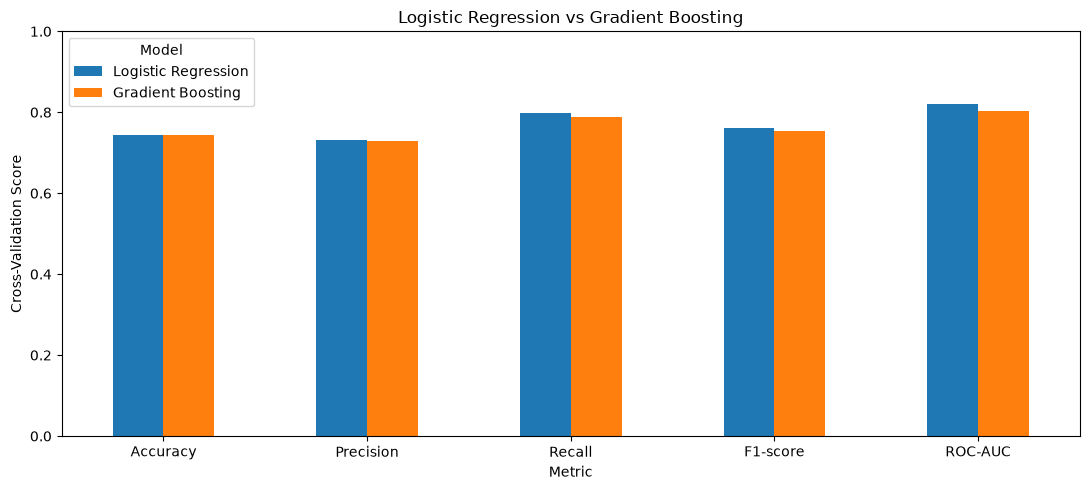

In [26]:
plot_data = comparison.set_index("Metric")

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title(
    "Logistic Regression vs Gradient Boosting"
)
ax.set_ylabel("Cross-Validation Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")

plt.tight_layout()
plt.show()

## Investigating Gradient Boosting Overfitting

The initial Gradient Boosting model achieved a training accuracy of 100%, while its mean cross-validation accuracy was approximately 74.51%.

This substantial difference suggests that the model may be overfitting the relatively small training dataset.

To investigate this issue, a simpler Gradient Boosting model was evaluated using shallower trees, fewer estimators, a lower learning rate, and a larger minimum leaf size.

Both configurations were evaluated using the same stratified 10-fold cross-validation procedure.

In [27]:
gb_simple_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.05,
        max_depth=1,
        min_samples_leaf=5,
        random_state=42
    ))
])

In [28]:
gb_simple_results = cross_validate(
    estimator=gb_simple_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Simplified Gradient Boosting Results")


for metric in scoring.keys():
    mean = gb_simple_results[f"test_{metric}"].mean()
    std = gb_simple_results[f"test_{metric}"].std()

    print(f"{metric.upper():12s}: {mean:.4f} ± {std:.4f}")

Simplified Gradient Boosting Results
ACCURACY    : 0.7049 ± 0.0888
PRECISION   : 0.6788 ± 0.0803
RECALL      : 0.8076 ± 0.0884
F1          : 0.7359 ± 0.0763
ROC_AUC     : 0.7708 ± 0.0834


In [29]:
overfitting_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Gradient Boosting",
        "Simplified Gradient Boosting"
    ],

    "Training Accuracy": [
        lr_cv_results["train_accuracy"].mean(),
        gb_cv_results["train_accuracy"].mean(),
        gb_simple_results["train_accuracy"].mean()
    ],

    "Validation Accuracy": [
        lr_cv_results["test_accuracy"].mean(),
        gb_cv_results["test_accuracy"].mean(),
        gb_simple_results["test_accuracy"].mean()
    ],

    "Validation ROC-AUC": [
        lr_cv_results["test_roc_auc"].mean(),
        gb_cv_results["test_roc_auc"].mean(),
        gb_simple_results["test_roc_auc"].mean()
    ]
})

overfitting_comparison["Generalization Gap"] = (
    overfitting_comparison["Training Accuracy"]
    - overfitting_comparison["Validation Accuracy"]
)

overfitting_comparison.round(4)

,Model,Training Accuracy,Validation Accuracy,Validation ROC-AUC,Generalization Gap
0,Logistic Regression,0.8605,0.7449,0.8213,0.1156
1,Original Gradient Boosting,1.0000,0.7451,0.8043,0.2549
2,Simplified Gradient Boosting,0.8002,0.7049,0.7708,0.0953



`The original Gradient Boosting model achieved 100% training accuracy but only 74.51% cross-validation accuracy, suggesting overfitting.The simplified Gradient Boosting model reduced the generalization gap from 25.49 to 9.53 percentage points. However, its validation accuracy decreased to 70.49%.`

`This suggests that the simpler model may be underfitting relative to the original configuration. I cannot conclude this definitively from one comparison, but it indicates that we need to balance model complexity and generalization.`

`The best result depends on the evaluation metric: original Gradient Boosting has slightly higher accuracy, while Logistic Regression has higher ROC-AUC.`


# 6. Comparative Evaluation of Ten Machine Learning Classifiers

Ten machine learning classifiers were implemented to compare their
predictive performance with the results reported by Esen et al. (2024).

The evaluated algorithms were Random Forest, Multilayer Perceptron,
Logistic Regression, Naive Bayes, Decision Tree, K-Nearest Neighbors,
Support Vector Machine, Gradient Boosting, AdaBoost, and XGBoost.

All models were evaluated using the same stratified 10-fold
cross-validation procedure on the training dataset.

Preprocessing was included within each model pipeline to prevent
data leakage during cross-validation.

The reported metrics include accuracy, precision, recall,
F1-score, and ROC-AUC.

In [30]:
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier)

from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate


In [31]:
def create_pipeline(model, scale=False):

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(
        ("classifier", model)
    )

    return Pipeline(steps)


models = {
    "RF": create_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "MLP": create_pipeline(
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=1000,
            random_state=42
        ),
        scale=True
    ),

    "LR": create_pipeline(
        LogisticRegression(
            max_iter=2000,
            random_state=42
        ),
        scale=True
    ),

    "NB": create_pipeline(
        GaussianNB()
    ),

    "DT": create_pipeline(
        DecisionTreeClassifier(
            random_state=42
        )
    ),

    "KNN": create_pipeline(
        KNeighborsClassifier(
            n_neighbors=5
        ),
        scale=True
    ),

    "SVM": create_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),
        scale=True
    ),

    "GB": create_pipeline(
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
    ),

    "AdaBoost": create_pipeline(
        AdaBoostClassifier(
            n_estimators=50,
            random_state=42
        )
    ),

    "XGBoost": create_pipeline(
        XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        )
    )
}

print("Number of models:", len(models))
print("Models:", list(models.keys()))

Number of models: 10
Models: ['RF', 'MLP', 'LR', 'NB', 'DT', 'KNN', 'SVM', 'GB', 'AdaBoost', 'XGBoost']


In [32]:
all_results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    cv_results = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    all_results.append({
        "Method": name,
        "Accuracy": cv_results["test_accuracy"].mean(),
        "Precision": cv_results["test_precision"].mean(),
        "Recall": cv_results["test_recall"].mean(),
        "F-measure": cv_results["test_f1"].mean(),
        "AUC": cv_results["test_roc_auc"].mean()
    })

our_results = pd.DataFrame(all_results)

our_results.round(4)

Evaluating RF...
Evaluating MLP...
Evaluating LR...
Evaluating NB...
Evaluating DT...
Evaluating KNN...
Evaluating SVM...
Evaluating GB...
Evaluating AdaBoost...
Evaluating XGBoost...


,Method,Accuracy,Precision,Recall,F-measure,AUC
0,RF,0.7360,0.7312,0.7621,0.7410,0.8262
1,MLP,0.7437,0.7269,0.8129,0.7639,0.7936
2,LR,0.7449,0.7316,0.7977,0.7608,0.8213
3,NB,0.5874,0.5624,0.8848,0.6841,0.6656
4,DT,0.6587,0.6643,0.6348,0.6445,0.6583
5,KNN,0.6140,0.5950,0.7697,0.6676,0.6849
6,SVM,0.7265,0.6987,0.8136,0.7489,0.7939
7,GB,0.7451,0.7296,0.7879,0.7540,0.8043
8,AdaBoost,0.7182,0.7087,0.7705,0.7313,0.7718
9,XGBoost,0.7447,0.7487,0.7682,0.7523,0.8094


### original paper's results

In [33]:
paper_results = pd.DataFrame({
    "Method": [
        "RF", "MLP", "LR", "NB", "DT",
        "KNN", "SVM", "GB", "AdaBoost", "XGBoost"
    ],

    "Paper Precision": [
        0.91, 0.76, 0.86, 0.61, 0.78,
        0.53, 0.52, 0.91, 0.86, 0.93
    ],

    "Paper Recall": [
        0.81, 0.56, 0.83, 0.87, 0.62,
        0.44, 0.29, 0.81, 0.81, 0.75
    ],

    "Paper F-measure": [
        0.86, 0.64, 0.84, 0.71, 0.69,
        0.48, 0.37, 0.86, 0.83, 0.83
    ],

    "Paper AUC": [
        0.85, 0.67, 0.83, 0.60, 0.70,
        0.49, 0.48, 0.85, 0.82, 0.84
    ]
})

paper_results

,Method,Paper Precision,Paper Recall,Paper F-measure,Paper AUC
0,RF,0.91,0.81,0.86,0.85
1,MLP,0.76,0.56,0.64,0.67
2,LR,0.86,0.83,0.84,0.83
3,NB,0.61,0.87,0.71,0.60
4,DT,0.78,0.62,0.69,0.70
5,KNN,0.53,0.44,0.48,0.49
6,SVM,0.52,0.29,0.37,0.48
7,GB,0.91,0.81,0.86,0.85
8,AdaBoost,0.86,0.81,0.83,0.82
9,XGBoost,0.93,0.75,0.83,0.84


In [34]:
comparison_10 = paper_results.merge(
    our_results,
    on="Method",
    how="inner"
)

comparison_10["Precision Difference"] = (
    comparison_10["Precision"]
    - comparison_10["Paper Precision"]
)

comparison_10["Recall Difference"] = (
    comparison_10["Recall"]
    - comparison_10["Paper Recall"]
)

comparison_10["F1 Difference"] = (
    comparison_10["F-measure"]
    - comparison_10["Paper F-measure"]
)

comparison_10["AUC Difference"] = (
    comparison_10["AUC"]
    - comparison_10["Paper AUC"]
)
comparison_10.round(4)

,Method,Paper Precision,Paper Recall,Paper F-measure,Paper AUC,Accuracy,Precision,Recall,F-measure,AUC,Precision Difference,Recall Difference,F1 Difference,AUC Difference
0,RF,0.91,0.81,0.86,0.85,0.7360,0.7312,0.7621,0.7410,0.8262,-0.1788,-0.0479,-0.1190,-0.0238
1,MLP,0.76,0.56,0.64,0.67,0.7437,0.7269,0.8129,0.7639,0.7936,-0.0331,0.2529,0.1239,0.1236
2,LR,0.86,0.83,0.84,0.83,0.7449,0.7316,0.7977,0.7608,0.8213,-0.1284,-0.0323,-0.0792,-0.0087
3,NB,0.61,0.87,0.71,0.60,0.5874,0.5624,0.8848,0.6841,0.6656,-0.0476,0.0148,-0.0259,0.0656
4,DT,0.78,0.62,0.69,0.70,0.6587,0.6643,0.6348,0.6445,0.6583,-0.1157,0.0148,-0.0455,-0.0417
5,KNN,0.53,0.44,0.48,0.49,0.6140,0.5950,0.7697,0.6676,0.6849,0.0650,0.3297,0.1876,0.1949
6,SVM,0.52,0.29,0.37,0.48,0.7265,0.6987,0.8136,0.7489,0.7939,0.1787,0.5236,0.3789,0.3139
7,GB,0.91,0.81,0.86,0.85,0.7451,0.7296,0.7879,0.7540,0.8043,-0.1804,-0.0221,-0.1060,-0.0457
8,AdaBoost,0.86,0.81,0.83,0.82,0.7182,0.7087,0.7705,0.7313,0.7718,-0.1513,-0.0395,-0.0987,-0.0482
9,XGBoost,0.93,0.75,0.83,0.84,0.7447,0.7487,0.7682,0.7523,0.8094,-0.1813,0.0182,-0.0777,-0.0306


## 7. Hyperparameter Optimization and Feature Selection

Hyperparameter optimization was performed to investigate whether
model performance could be improved beyond the initial baseline
configurations.

Logistic Regression, Random Forest, and Gradient Boosting were
selected for further investigation based on their baseline
performance and relevance to the original paper.

ANOVA F-test feature selection was incorporated within
Scikit-learn pipelines to prevent data leakage.

GridSearchCV was used with stratified 10-fold cross-validation
on the training dataset.

ROC-AUC was selected as the optimization metric because it
evaluates discrimination across classification thresholds.

The independent test dataset was not used during tuning.

In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif


In [36]:
tuning_models = {

    "LR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("anova", SelectKBest(score_func=f_classif)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("anova", SelectKBest(score_func=f_classif)),
        ("classifier", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]),

    "GB": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("anova", SelectKBest(score_func=f_classif)),
        ("classifier", GradientBoostingClassifier(
            random_state=42
        ))
    ])
}

print("Models prepared:", list(tuning_models.keys()))

Models prepared: ['LR', 'RF', 'GB']


In [37]:
param_grids = {

    "LR": {
        "anova__k": [10, 20, 32, "all"],
        "classifier__C": [0.01, 0.1, 1, 10]
    },

    "RF": {
        "anova__k": [10, 20, 32, "all"],
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5, None],
        "classifier__min_samples_leaf": [1, 3]
    },

    "GB": {
        "anova__k": [10, 20, 32, "all"],
        "classifier__n_estimators": [50, 100],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [1, 2, 3]
    }
}

print("Hyperparameter grids configured!")

Hyperparameter grids configured!


In [38]:
grid_searches = {}
tuning_results = []

for name, pipeline in tuning_models.items():

    print(f"\nTuning {name}...")

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=disease_auc,
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    grid.fit(X_train, y_train)

    grid_searches[name] = grid

    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best ROC-AUC:", round(grid.best_score_, 4))
    print("Best parameters:", grid.best_params_)

tuning_summary = pd.DataFrame(tuning_results)

tuning_summary


Tuning LR...
Best ROC-AUC: 0.8446
Best parameters: {'anova__k': 20, 'classifier__C': 10}

Tuning RF...
Best ROC-AUC: 0.8484
Best parameters: {'anova__k': 20, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

Tuning GB...
Best ROC-AUC: 0.8475
Best parameters: {'anova__k': 10, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}


,Model,Best CV ROC-AUC,Best Parameters
0,LR,0.844628,"{'anova__k': 20, 'classifier__C': 10}"
1,RF,0.848382,"{'anova__k': 20, 'classifier__max_depth': None..."
2,GB,0.847452,"{'anova__k': 10, 'classifier__learning_rate': ..."


In [39]:
baseline_auc = {
    "LR": our_results.loc[
        our_results["Method"] == "LR", "AUC"
    ].iloc[0],

    "RF": our_results.loc[
        our_results["Method"] == "RF", "AUC"
    ].iloc[0],

    "GB": our_results.loc[
        our_results["Method"] == "GB", "AUC"
    ].iloc[0]
}

tuning_comparison = pd.DataFrame({
    "Model": ["LR", "RF", "GB"],

    "Baseline CV AUC": [
        baseline_auc["LR"],
        baseline_auc["RF"],
        baseline_auc["GB"]
    ],

    "Best GridSearch CV AUC": [
        grid_searches["LR"].best_score_,
        grid_searches["RF"].best_score_,
        grid_searches["GB"].best_score_
    ]
})

tuning_comparison["Difference"] = (
    tuning_comparison["Best GridSearch CV AUC"]
    - tuning_comparison["Baseline CV AUC"]
)

tuning_comparison.round(4)

,Model,Baseline CV AUC,Best GridSearch CV AUC,Difference
0,LR,0.8213,0.8446,0.0233
1,RF,0.8262,0.8484,0.0222
2,GB,0.8043,0.8475,0.0432


## 8. Nested Cross-Validation

Nested cross-validation was used to assess the generalization
performance of the hyperparameter optimization procedure.

An outer stratified 5-fold cross-validation loop was used
for model evaluation.

Within each outer training fold, an inner stratified 5-fold
cross-validation loop was used for hyperparameter selection.

ANOVA feature selection and preprocessing were performed
inside each training pipeline.

The independent test dataset was not used during this process.

In [40]:
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

print("Outer folds:", outer_cv.get_n_splits())
print("Inner folds:", inner_cv.get_n_splits())

Outer folds: 5
Inner folds: 5


In [41]:
nested_results = []

for name in ["LR", "RF", "GB"]:

    print(f"\nNested CV for {name}...")

    inner_search = GridSearchCV(
        estimator=tuning_models[name],
        param_grid=param_grids[name],
        scoring=disease_auc,
        cv=inner_cv,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    scores = cross_validate(
        estimator=inner_search,
        X=X_train,
        y=y_train,
        cv=outer_cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1,
        error_score="raise"
    )

    nested_results.append({
        "Model": name,
        "Nested Accuracy": scores["test_accuracy"].mean(),
        "Nested Precision": scores["test_precision"].mean(),
        "Nested Recall": scores["test_recall"].mean(),
        "Nested F1": scores["test_f1"].mean(),
        "Nested ROC-AUC": scores["test_roc_auc"].mean(),
        "AUC Std": scores["test_roc_auc"].std()
    })

nested_summary = pd.DataFrame(nested_results)

nested_summary.round(4)


Nested CV for LR...

Nested CV for RF...

Nested CV for GB...


,Model,Nested Accuracy,Nested Precision,Nested Recall,Nested F1,Nested ROC-AUC,AUC Std
0,LR,0.7711,0.7613,0.8138,0.7821,0.8134,0.0926
1,RF,0.7131,0.7123,0.7344,0.7187,0.7866,0.0267
2,GB,0.6997,0.6839,0.7783,0.7225,0.7673,0.0343


In [42]:
nested_comparison = tuning_comparison.merge(
    nested_summary[
        ["Model", "Nested ROC-AUC", "AUC Std"]
    ],
    on="Model"
)

nested_comparison["Selection Optimism"] = (
    nested_comparison["Best GridSearch CV AUC"]
    - nested_comparison["Nested ROC-AUC"]
)

nested_comparison.round(4)

,Model,Baseline CV AUC,Best GridSearch CV AUC,Difference,Nested ROC-AUC,AUC Std,Selection Optimism
0,LR,0.8213,0.8446,0.0233,0.8134,0.0926,0.0312
1,RF,0.8262,0.8484,0.0222,0.7866,0.0267,0.0617
2,GB,0.8043,0.8475,0.0432,0.7673,0.0343,0.0801


## 9. Final Model Selection and Independent Test Evaluation

Logistic Regression was selected as the primary final model
because it achieved the highest accuracy and ROC-AUC among
the three algorithms evaluated using nested cross-validation.

The selected Logistic Regression pipeline was refitted using
the full training dataset of 223 observations.

The independent test dataset containing 96 observations was
then used to evaluate its predictive performance.

The test dataset was not used for hyperparameter optimization
or model selection.

Evaluation metrics included accuracy, precision, recall,
F1-score, specificity, ROC-AUC, and confusion matrix.

In [43]:
from sklearn.base import clone

final_model = clone(
    grid_searches["LR"].best_estimator_
)

final_model.fit(X_train, y_train)

print("Final model: Logistic Regression")
print("Training records:", len(X_train))

print("\nSelected hyperparameters:")
print(grid_searches["LR"].best_params_)

Final model: Logistic Regression
Training records: 223

Selected hyperparameters:
{'anova__k': 20, 'classifier__C': 10}


In [44]:
import numpy as np

y_pred = final_model.predict(X_test)

# Probability of gallstones being present (class 0)
class_index = list(final_model.classes_).index(0)

y_proba = final_model.predict_proba(
    X_test
)[:, class_index]

print("Number of test predictions:", len(y_pred))
print("Predicted gallstone patients:", np.sum(y_pred == 0))
print("Predicted healthy patients:", np.sum(y_pred == 1))

Number of test predictions: 96
Predicted gallstone patients: 49
Predicted healthy patients: 47


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=0
)

recall = recall_score(
    y_test, y_pred, pos_label=0
)

f1 = f1_score(
    y_test, y_pred, pos_label=0
)

auc = roc_auc_score(
    (y_test == 0).astype(int),
    y_proba
)

# Confusion matrix ordered as:
# 0 = Gallstones Present, 1 = Healthy
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]

specificity = TN / (TN + FP)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        auc
    ]
})

final_metrics.round(4)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Gallstones Present",
            "Healthy"
        ]
    )
)


Classification Report:
                    precision    recall  f1-score   support

Gallstones Present       0.82      0.83      0.82        48
           Healthy       0.83      0.81      0.82        48

          accuracy                           0.82        96
         macro avg       0.82      0.82      0.82        96
      weighted avg       0.82      0.82      0.82        96



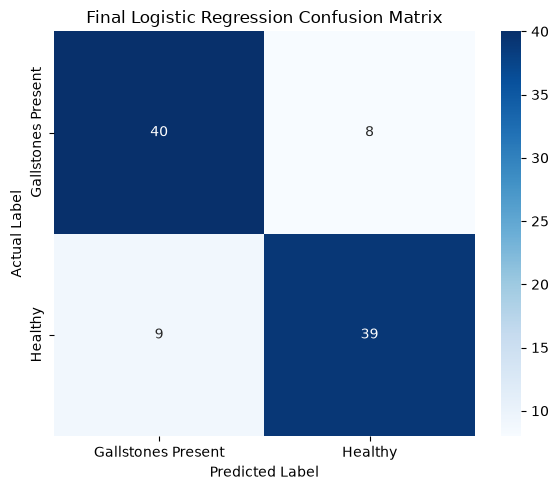

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Gallstones Present",
        "Healthy"
    ],
    yticklabels=[
        "Gallstones Present",
        "Healthy"
    ]
)

plt.title("Final Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

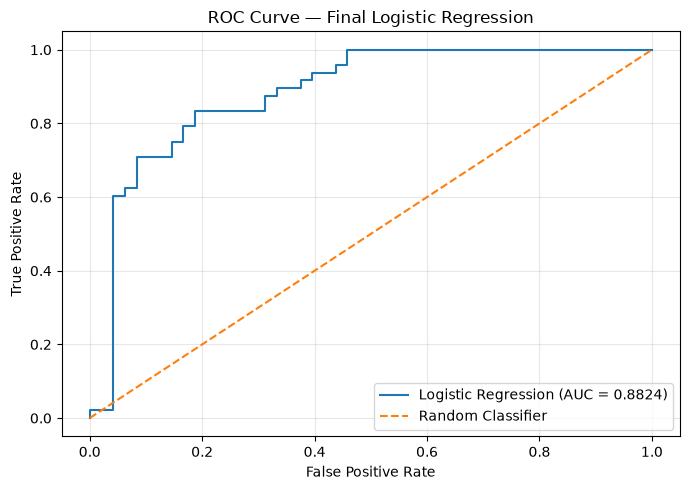

In [47]:
from sklearn.metrics import roc_curve

disease_true = (y_test == 0).astype(int)

fpr, tpr, thresholds = roc_curve(
    disease_true,
    y_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
paper_lr = {
    "Precision": 0.86,
    "Recall": 0.83,
    "F1-score": 0.84,
    "ROC-AUC": 0.83
}

our_lr = {
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "ROC-AUC": auc
}

final_comparison = pd.DataFrame({
    "Metric": list(paper_lr.keys()),
    "Paper LR": list(paper_lr.values()),
    "Our Final LR": list(our_lr.values())
})

final_comparison["Difference"] = (
    final_comparison["Our Final LR"]
    - final_comparison["Paper LR"]
)

final_comparison.round(4)

,Metric,Paper LR,Our Final LR,Difference
0,Precision,0.86,0.8163,-0.0437
1,Recall,0.83,0.8333,0.0033
2,F1-score,0.84,0.8247,-0.0153
3,ROC-AUC,0.83,0.8824,0.0524


In [49]:
# Access the fitted ANOVA feature selector
selector = final_model.named_steps["anova"]

# Retrieve selected feature names
selected_features = X_train.columns[
    selector.get_support()
]

print("Number of selected features:", len(selected_features))

print("\nSelected features:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

Number of selected features: 20

Selected features:
1. Gender
2. Coronary Artery Disease (CAD)
3. Hyperlipidemia
4. Diabetes Mellitus (DM)
5. Height
6. Total Body Water (TBW)
7. Extracellular Water (ECW)
8. Extracellular Fluid/Total Body Water (ECF/TBW)
9. Total Body Fat Ratio (TBFR) (%)
10. Lean Mass (LM) (%)
11. Bone Mass (BM)
12. Muscle Mass (MM)
13. Total Fat Content (TFC)
14. Visceral Muscle Area (VMA) (Kg)
15. High Density Lipoprotein (HDL)
16. Aspartat Aminotransferaz (AST)
17. Creatinine
18. C-Reactive Protein (CRP)
19. Hemoglobin (HGB)
20. Vitamin D


In [50]:
selector = final_model.named_steps["anova"]

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "ANOVA F-score": selector.scores_,
    "Selected": selector.get_support()
})

selected_scores = (
    feature_scores[feature_scores["Selected"]]
    .sort_values("ANOVA F-score", ascending=False)
)

selected_scores.round(4)

,Feature,ANOVA F-score,Selected
37,Vitamin D,30.7599,True
35,C-Reactive Protein (CRP),17.2192,True
18,Bone Mass (BM),13.3597,True
15,Lean Mass (LM) (%),8.7994,True
11,Extracellular Water (ECW),8.6949,True
14,Total Body Fat Ratio (TBFR) (%),8.3117,True
30,Aspartat Aminotransferaz (AST),7.9085,True
5,Hyperlipidemia,6.4608,True
28,High Density Lipoprotein (HDL),5.8241,True
10,Total Body Water (TBW),4.6427,True


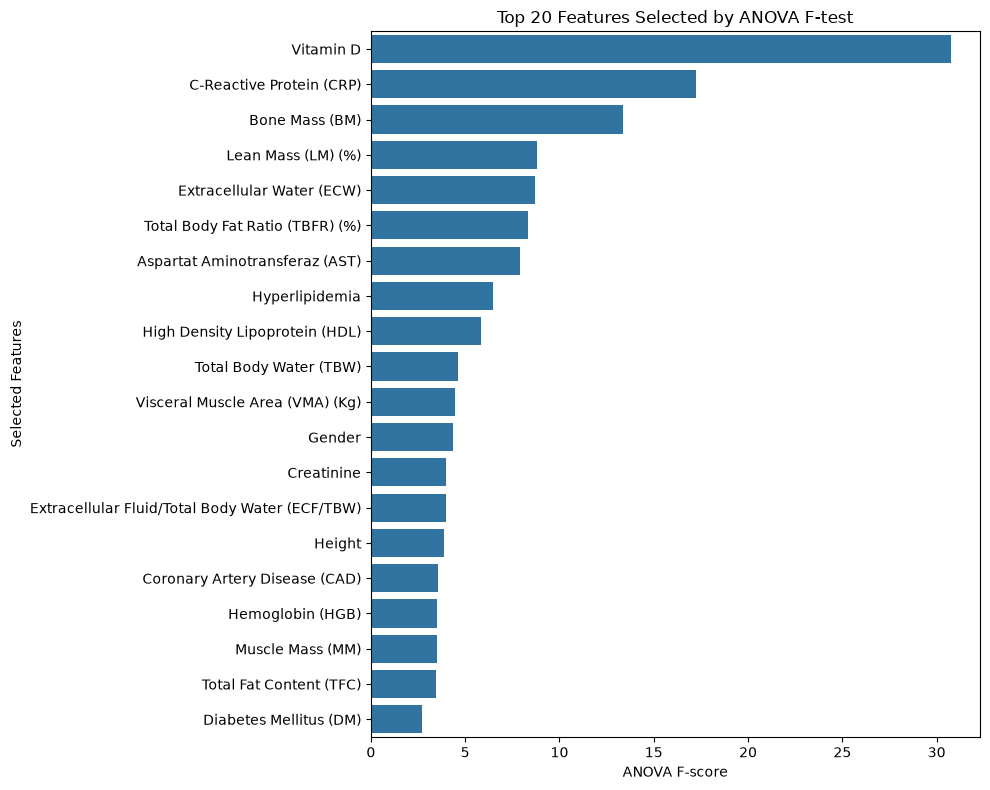

In [51]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=selected_scores,
    x="ANOVA F-score",
    y="Feature"
)

plt.title("Top 20 Features Selected by ANOVA F-test")
plt.xlabel("ANOVA F-score")
plt.ylabel("Selected Features")

plt.tight_layout()
plt.show()

# Phase 2 – What I Implemented and Achieved

In Phase 2, I worked with the gallstone disease dataset used in the research paper by Esen et al. (2024).

My main goal was to build a simple machine learning baseline, compare it with the original paper's results, and understand how different machine learning algorithms perform on the same dataset.

I started with Logistic Regression and Gradient Boosting. After that, I tested all ten algorithms from the paper and tried different methods to improve and evaluate their performance.

## What I Did

### 1. Explored the Dataset

I loaded the original dataset and checked its structure.

- 319 patient records
- 38 input features
- 161 patients with gallstones
- 158 healthy patients
- No missing values or duplicate records

I also checked feature distributions, correlations, skewness, and outliers.

### 2. Prepared the Data

I divided the dataset into:

- 223 training records (70%)
- 96 testing records (30%)

I used stratified splitting to keep the class distribution balanced.

For model evaluation, I used stratified 10-fold cross-validation.

### 3. Built My First Baseline Models

I first implemented Logistic Regression and Gradient Boosting.

| Model | CV Accuracy | CV ROC-AUC |
|---|---:|---:|
| Logistic Regression | 74.49% | 0.8213 |
| Gradient Boosting | 74.51% | 0.8043 |

Gradient Boosting achieved 100% training accuracy but only 74.51% validation accuracy.

This showed me that the model was likely overfitting.

I then tried a simpler Gradient Boosting model. Its validation accuracy decreased to 70.49%, although its generalization gap became smaller.

### 4. Tested All Ten Algorithms from the Paper

I implemented Random Forest, MLP, Logistic Regression, Naive Bayes, Decision Tree, KNN, SVM, Gradient Boosting, AdaBoost, and XGBoost.

All models were evaluated using the same cross-validation procedure.

I found that:

- Gradient Boosting had the highest initial accuracy (74.51%).
- Random Forest had the highest initial ROC-AUC (0.8262).
- XGBoost had the highest precision (74.87%).
- Naive Bayes had the highest recall (88.48%).
- MLP had the highest F1-score (0.7639).

This helped me understand that different algorithms can perform better depending on which evaluation metric is used.

### 5. Tried Hyperparameter Tuning

Next, I used GridSearchCV to tune three models: Logistic Regression, Random Forest, and Gradient Boosting.

| Model | Before Tuning AUC | Best GridSearchCV AUC |
|---|---:|---:|
| Logistic Regression | 0.8213 | 0.8446 |
| Random Forest | 0.8262 | 0.8484 |
| Gradient Boosting | 0.8043 | 0.8475 |

The tuning process produced higher cross-validation scores for all three models.

However, I learned that these scores alone do not guarantee better performance on unseen data.

### 6. Checked the Models Using Nested Cross-Validation

I used nested cross-validation with five outer folds and five inner folds to evaluate the tuning process more carefully.

| Model | Nested CV Accuracy | Nested CV AUC |
|---|---:|---:|
| Logistic Regression | 77.11% | 0.8134 |
| Random Forest | 71.31% | 0.7866 |
| Gradient Boosting | 69.97% | 0.7673 |

Logistic Regression performed best among these three models.

Based on these results, I selected Logistic Regression as my final model.

### 7. Selected the Best Features

I used ANOVA F-test feature selection inside the model pipeline.

From the original 38 features, GridSearchCV selected 20 features for the final Logistic Regression model.

The five highest-ranked features were:

| Feature | ANOVA F-score |
|---|---:|
| Vitamin D | 30.7599 |
| CRP | 17.2192 |
| Bone Mass | 13.3597 |
| Lean Mass | 8.7994 |
| Extracellular Water | 8.6949 |

This helped me identify which features showed stronger individual statistical relationships with gallstone status.

### 8. Tested My Final Model

Finally, I trained the selected Logistic Regression model using all 223 training records and tested it on the remaining 96 records.

`My final results:`

| Metric | Result |
|---|---:|
| Accuracy | `82.29%` |
| Precision | 81.63% |
| Recall | 83.33% |
| Specificity | 81.25% |
| F1-score | 82.47% |
| ROC-AUC | `0.8824` |

The model correctly predicted 79 out of 96 patients.

It correctly identified 40 patients with gallstones and 39 healthy patients. It also made 17 incorrect predictions.

### 9. Compared My Results with the Paper

I compared my final Logistic Regression results with those reported in the original research.

| Metric | Paper LR | My LR |
|---|---:|---:|
| Precision | 0.86 | 0.8163 |
| Recall | 0.83 | 0.8333 |
| F1-score | 0.84 | 0.8247 |
| ROC-AUC | 0.83 | `0.8824` |

My model achieved a higher ROC-AUC than the paper's reported Logistic Regression result, but slightly lower precision and F1-score.

The evaluation methods may differ, so this does not prove that my model is better than the authors' model.

By the end of Phase 2, I had implemented and compared all ten machine learning algorithms from the paper.

I also experimented with overfitting, hyperparameter tuning, ANOVA feature selection, and nested cross-validation.

`My final selected model was Logistic Regression with 20 features and C = 10. It achieved 82.29% accuracy and 0.8824 ROC-AUC on the held-out test dataset.`

The biggest thing was that a more complex algorithm does not always give better results. Logistic Regression performed better than the tuned Random Forest and Gradient Boosting models in my nested cross-validation experiment.
